In [3]:
import numpy as np
H, W = 5, 7
WALLS = {(1,2), (2,2), (3,2), (1,4), (2,4)}
GOAL, PIT, START = (0, W-1), (2, W-1), (H-1, 0)
A = [(-1,0), (1,0), (0,-1), (0,1)] # up, down, left, right

def step(s, a):
 r, c = s; dr, dc = A[a]; nr, nc = r+dr, c+dc
 if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
  nr, nc = r, c # bumping a wall wastes the step
 ns = (nr, nc)
 if ns == GOAL: return ns, +10.0, True
 if ns == PIT: return ns, -10.0, True
 return ns, -0.1, False # small cost per step

In [4]:
def train(eps, episodes=600, alpha=0.5, gamma=0.95, seed=0):
 rng = np.random.default_rng(seed)
 Q = np.zeros((H, W, 4))
 curve = []
 for _ in range(episodes):
  s, total = START, 0.0
  for _ in range(120): # step cap
    if rng.random() < eps:
      a = rng.integers(4) # explore
    else:
      a = int(np.argmax(Q[s[0], s[1]])) # exploit
    ns, r, done = step(s, a)
    total += r
    Q[s[0], s[1], a] += alpha * (
      r + gamma*np.max(Q[ns[0], ns[1]])*(not done) - Q[s[0], s[1], a])
    s = ns
    if done: break
  curve.append(total)
 return Q, np.array(curve)


eps=0.05: mean return over last 100 episodes = 8.86
eps=0.2: mean return over last 100 episodes = 8.86
eps=0.5: mean return over last 100 episodes = 7.44


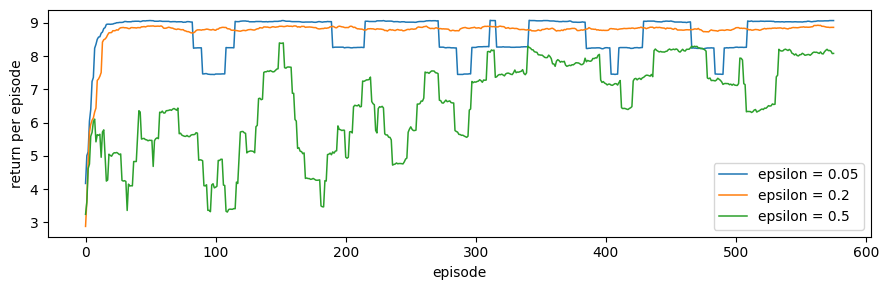

Date: 22-09-2026 and Time: 08:42:09


In [6]:
import matplotlib.pyplot as plt

def smooth(v, k=25):
 return np.convolve(v, np.ones(k)/k, mode='valid')

plt.figure(figsize=(9, 3))
for eps in (0.05, 0.20, 0.50):
 Q, curve = train(eps)
 plt.plot(smooth(curve), lw=1.1, label=f'epsilon = {eps}')
 print(f'eps={eps}: mean return over last 100 episodes ='
 f' {curve[-100:].mean():.2f}')
plt.xlabel('episode'); plt.ylabel('return per episode')
plt.legend(); plt.tight_layout(); plt.show()

Q, _ = train(0.20)
policy = np.argmax(Q, axis=2) # greedy action in every cell

import datetime
import pytz

utc_now = datetime.datetime.now(datetime.UTC)
ist_timezone = pytz.timezone('Asia/Kolkata')
ist_now = utc_now.astimezone(ist_timezone)

print(f"Date: {ist_now.strftime('%d-%m-%Y')} and Time: {ist_now.strftime('%H:%M:%S')}")

In [7]:
import numpy as np

X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0] ], dtype=float) # XOR

def sigmoid(z):
 return 1 / (1 + np.exp(-z))

rng = np.random.default_rng(1)
hidden = 4
W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))

h = sigmoid(X @ W1 + b1) # hidden activations, 4 x hidden
o = sigmoid(h @ W2 + b2) # output, 4 x 1
print('initial loss:', float(np.mean((o - y)**2)))


initial loss: 0.2748629616482994


In [8]:
def train_xor(lr, epochs=20000, seed=1, hidden=4):
 rng = np.random.default_rng(seed)
 W1 = rng.normal(0, 1, (2, hidden)); b1 = np.zeros((1, hidden))
 W2 = rng.normal(0, 1, (hidden, 1)); b2 = np.zeros((1, 1))
 loss = []
 for _ in range(epochs):
   h = sigmoid(X @ W1 + b1) # forward
   o = sigmoid(h @ W2 + b2)
   loss.append(float(np.mean((o - y)**2)))
   do = (o - y) * o * (1 - o) # backward
   dW2 = h.T @ do; db2 = do.sum(0, keepdims=True)
   dh = (do @ W2.T) * h * (1 - h)
   dW1 = X.T @ dh; db1 = dh.sum(0, keepdims=True)
   W2 -= lr*dW2; b2 -= lr*db2 # gradient descent
   W1 -= lr*dW1; b1 -= lr*db1
 return (W1, b1, W2, b2), np.array(loss)

params, loss = train_xor(2.0)
W1, b1, W2, b2 = params
print('final loss:', loss[-1])
print('predictions:', sigmoid(sigmoid(X @ W1 + b1) @ W2 + b2).ravel().round(3))


final loss: 2.4552864803967283e-05
predictions: [0.004 0.995 0.996 0.006]


lr=0.05: final MSE = 2.31e-03
lr=0.5: final MSE = 1.11e-04
lr=2.0: final MSE = 2.46e-05


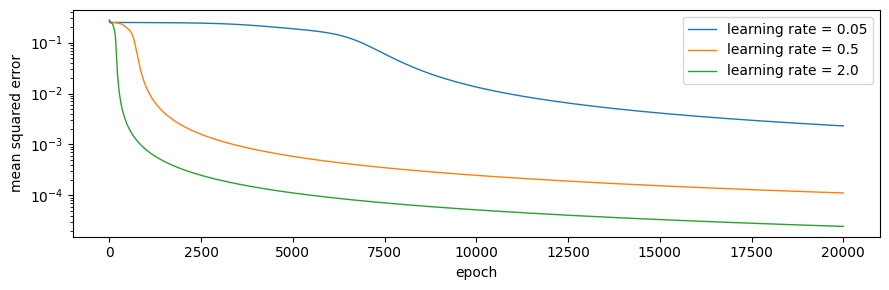

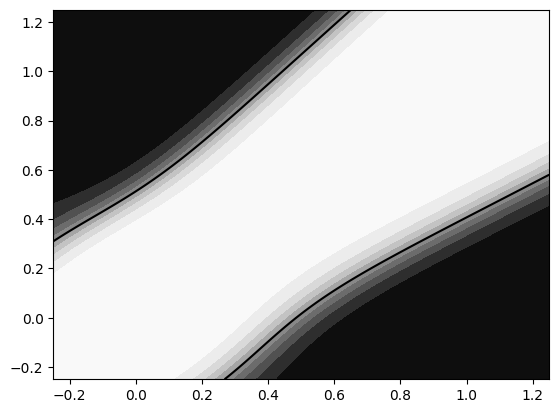

Date: 22-09-2026 and Time: 09:34:19


In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 3))
for lr in (0.05, 0.5, 2.0):
  _, l = train_xor(lr)
  plt.semilogy(l, lw=1.0, label=f'learning rate = {lr}')
  print(f'lr={lr}: final MSE = {l[-1]:.2e}')
plt.xlabel('epoch'); plt.ylabel('mean squared error'); plt.legend()
plt.tight_layout(); plt.show()

gx, gy = np.meshgrid(np.linspace(-0.25, 1.25, 300),
np.linspace(-0.25, 1.25, 300))
G = np.c_[gx.ravel(), gy.ravel()]
Z = sigmoid(sigmoid(G @ W1 + b1) @ W2 + b2).reshape(gx.shape)
plt.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap='Greys')
plt.contour(gx, gy, Z, levels=[0.5], colors='k')
plt.show()


utc_now = datetime.datetime.now(datetime.UTC)
ist_timezone = pytz.timezone('Asia/Kolkata')
ist_now = utc_now.astimezone(ist_timezone)

print(f"Date: {ist_now.strftime('%d-%m-%Y')} and Time: {ist_now.strftime('%H:%M:%S')}")